# Lecture 22: Relaxation Methods and Partial Differential Equations

In addition to time-dependent partial differential equations, one often also has to solve a partial differential equations to calculate the steady-state solution of a number of quantities. Such examples include the gravitational potential of an extended mass distribution, or the hydrostatic equilibrium of a star. Such partial differential equations are *hyperbolic*, and take a different set of algorithms to solve, called *relaxation methods.* This lecture discusses how these algorithms work in one dimension, but they can be generalized to two or three dimensions as well.

In addition to the lecture material below, all students also need to download `lec22_module.py` using the command below:
```bash
curl -O https://raw.githubusercontent.com/PsuAstro410/psuastro410.github.io/refs/heads/main/lectures/lec22_module.py
```

### Accepting and submitting

To accept this assignment on Classroom 50 with your GitHub profile enrolled in the class, click on the link \
https://classroom50.org/PsuAstro410/410astro26/assignments/lecture-22/accept \
and follow the steps the webpage prompts.

To submit this assignment, follow the steps in "First time Classroom 50 setup" and "Accepting and Submitting Assignments" on the course webpage:\
https://psuastro410.github.io/tips/github/

### Resources and Acknowledgements

We have used material from the following sources: \
https://zingale.github.io/computational_astrophysics/elliptic_multigrid/intro/elliptic-problems.html

In [1]:
# Nice things to have this lecture
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import lec22_module as pdemod
import sympy as sp

# Poisson problem

Consider the Poisson equation

$$\nabla^2 \phi = f$$

This is a second-order elliptic equation, and therefore requires 2 boundary conditions.

**Note:**
There is no time-dependence in this equation.  The potential $\phi$
responds instantaneously to the source $f$ and the boundary
conditions.

Consider the one-dimensional Poisson equation:

$$\phi^{\prime\prime} = f$$

on the domain $[a, b]$.

At each boundary. we can specify the boundary conditions as

* [Dirichlet](https://en.wikipedia.org/wiki/Dirichlet_boundary_condition): $\phi(a) = A$
* [Neumann](https://en.wikipedia.org/wiki/Neumann_boundary_condition): $\phi^\prime(a) = C$
* [Robin](https://en.wikipedia.org/wiki/Robin_boundary_condition): $\alpha \phi(a) + \beta \phi^\prime(a) = \gamma$ (a mix of the above two)
* periodic

We can also have different boundary conditions on each boundary.
If the values are set to 0, we call the
conditions homogeneous, otherwise we call them inhomogeneous.

**Note:**
Not any set of boundary conditions is allowed.
Consider $f = 0$, so our Poisson equation (is the Laplace equation):
$$\phi^{\prime\prime} = 0$$
and the solution is just
$$\phi(x) = a x + b$$
if we try to enforce different inhomogeneous Neumann boundary
conditions on each end, then we get conflicting values for the
slope&mdash;this is unsolvable.

To understand solvable boundary conditions for the general case, 

$$\nabla^2 \phi = f$$

we start by integrating over the domain

$$\int_\Omega \nabla^2 \phi d\Omega = \int_{\partial \Omega} \nabla \phi \cdot {\bf n} dS = \int_\Omega f d\Omega$$

If we have homogeneous Neumann BCs on all sides, $\nabla \phi \cdot
{\bf n} = 0$, then the source, $f$, must satisfy

$$\int_\Omega f d\Omega = 0$$

The same condition will apply if the boundary conditions are periodic.

# Relaxation

A second-order accurate discretization of the second derivative is:

$$\phi_i^{\prime\prime} = \frac{\phi_{i+1} - 2\phi_i + \phi_{i-1}}{\Delta x^2}$$

**Note:**
This is true on finite-difference and finite-volume grids (to second-order in $\Delta x$).

We'll work in 1-d.  Our
Poisson equation

$$\phi^{\prime\prime} = f$$

becomes:

$$\frac{\phi_{i+1} - 2\phi_i + \phi_{i-1}}{\Delta x^2} = f_i$$


Using this discretization for all zones i in $0, \ldots, N-1$ results
in $N$ coupled algebraic equations.

**Note:**
We could solve this by writing it as a linear system,
${\bf A}{\bf x} = {\bf b}$, with ${\bf A}$ a triadiagonal matrix with
diagonals $1, -2, 1$ and $b$ corresponding to $f_i$.  This approach is a
"direct solve" of the coupled system.  But this can be expensive in
multi-dimensions and harder to parallelize if [domain decomposition](https://en.wikipedia.org/wiki/Domain_decomposition_methods) is used.

Instead of directly solving the linear system, we can use
[relaxation](https://en.wikipedia.org/wiki/Relaxation_(iterative_method))&mdash;an
iterative approach that converges to the solution.

We solve for the update for a single zone:

$$\phi_i = \frac{1}{2} ( \phi_{i+1} + \phi_{i-1} - \Delta x^2 f_i ) $$

and then iteratively use this expression to update the zones one by one.


**Tip:**
Relaxation is often also called _smoothing_ because the trend is to make
the solution smoother as we iterate.

Generally relaxation requires that the matrix be [*diagonally
dominant*](https://en.wikipedia.org/wiki/Diagonally_dominant_matrix),
which we are just shy of, but nevertheless, relaxation works quite
well for this system.

## Smoothing types

There are a few popular approaches we can
consider:

* [*Jacobi iteration*](https://en.wikipedia.org/wiki/Jacobi_method) :
  * pick an initial guess $\phi_i^{(0)}$ for all $i$
  * Improve the guess via relaxation:

    $$\phi_i^{(k+1)} = \frac{1}{2} ( \phi_{i+1}^{(k)} + \phi_{i-1}^{(k)} - \Delta x^2 f_i )$$

  * Assess the error, and if needed iterate

* [*Gauss-Seidel (G-S) iteration*](https://en.wikipedia.org/wiki/Gauss%E2%80%93Seidel_method) :

  * pick an initial guess $\phi_i^{(0)}$ for all $i$

  * use the new data as it becomes available:

    $$\phi_i \leftarrow \frac{1}{2} ( \phi_{i+1} + \phi_{i-1} - \Delta x^2 f_i )$$

    Note that there are no iteration superscripts indicated here,
    since we are not keeping the old and new $\phi$ separate in
    memory.  We keep only a single $\phi$ and update it as we sweep
    from $i = 0, \ldots, N-1$.

* *Red-black Gauss-Seidel*: this is a variation on G-S iteration that does the update
  of the odd and even zones separately.  The name comes from thinking about a checkerboard:
  with our update, the black squares depend only on the red and the red squares depend only
  on the black.  So we can update them in 2 separate passes.

  * First update the odd points&mdash;they only depend on the values at
    the even points

  * Next update the even points&mdash;they only depend on the values of
    the odd points

  The advantage of this is that it makes it much easier to parallelize
  via domain decomposition.  We'll use this approach going forward.

**Note:**
One can solve this type of boundary value problem using
[shooting](https://zingale.github.io/computational_astrophysics/ODEs/boundary-value-problems.html).
Why are we redoing it now using relaxation, which is an iterative process? The answer is that shooting only works for a 1D Poisson equation, but relaxation extends
easily to 2- and 3D.  There is a powerful technique called _multigrid_
that can accelerate the convergence of relaxation. Unfortunately, we will not have a chance to discuss this technique in this course.

## Boundary conditions

We need to pay special attention to the boundaries.  This depends on
what type of grid we are using.

For a finite difference (node-centered) grid:

![finite-difference grid](https://zingale.github.io/computational_astrophysics/_images/fd_grid_bnd.png)

we have a point exactly on each boundary, so we only need to iterate
over the interior points.

In contrast, for a finite-volume or cell-centered finite-difference grid:

![finite-volume grid](https://zingale.github.io/computational_astrophysics/_images/ccfd_grid_bnd.png)

we don't have data on the physical boundaries, so we will need to
interpolate to the boundary.

We'll work with a cell-centered grid, with a single ghost cell (needed
to set the boundary conditions).  We'll label the first interior zone
as `lo` and the last interior zone as `hi`.  Imagine that the domain
runs from $[a, b]$.

![cell-centered finite difference grid with labels](https://zingale.github.io/computational_astrophysics/_images/ccfd_ghost.png)

Consider the following boundary conditions:

* Dirichlet: we need the value on the boundary itself to satisfy the
  boundary condition:

  $$\phi(a) = A$$

  **Caution:**
  A naive guess would be to set $\phi_{\mathrm{lo}-1} = A$, but this
  is only first order accurate.

  We recognize that we can average across the boundary to be
  second-onder on the boundary:

  $$A = \frac{\phi_\mathrm{lo} + \phi_\mathrm{lo-1}}{2}$$

  which gives the ghost cell value:

  $$\phi_{\mathrm{lo}-1} = 2 A - \phi_\mathrm{lo}$$


* Neumann: we need a gradient, centered at the boundary to match the
  given value:

  $$\phi^\prime(a) = C$$

  A second-order accurate discretization on the boundary is:

  $$C = \frac{\phi_\mathrm{lo} - \phi_\mathrm{lo-1}}{\Delta x}$$

  so we would initialize the ghost cell as:

  $$\phi_{\mathrm{lo}-1} = \phi_\mathrm{lo} -\Delta x C$$



# Implementing Relaxation

## Grid Class

Let's start by overviewing the grid class that holds the solution and RHS and knows how to fill ghost cells.  Much of this class is identical to what we've done before, stored within the `lec22_module.py` module, written within the larger `PoissonRelaxation` class. However, when we create an object of this class, we also have the option of specifying the boundary conditions. This can be seen in the ``def __init__`` portion of the script
```python
class Grid:
    def __init__(self, nx, ng=1, xmin=0, xmax=1,
                 bc_left_type="dirichlet", bc_left_val=0.0,
                 bc_right_type="dirichlet", bc_right_val=0.0):
```
These boundary condition attributes are later set explicitly:
```python
        self.bc_left_type = bc_left_type
        self.bc_left_val = bc_left_val
        
        self.bc_right_type = bc_right_type
        self.bc_right_val = bc_right_val
```
The `fill_BCs` module later on has also been modified to explicitly include different boundary condition types:
```python
    def fill_BCs(self):
        """fill the boundary conditions on phi"""
        
        # we only deal with a single ghost cell here
        
        # left
        if self.bc_left_type.lower() == "dirichlet":
            self.phi[self.ilo-1] = 2 * self.bc_left_val - self.phi[self.ilo]
        elif self.bc_left_type.lower() == "neumann":
            self.phi[self.ilo-1] = self.phi[self.ilo] - self.dx * self.bc_left_val
        else:
            raise ValueError("invalid bc_left_type")
            
        # right
        if self.bc_right_type.lower() == "dirichlet":
            self.phi[self.ihi+1] = 2 * self.bc_right_val - self.phi[self.ihi]
        elif self.bc_right_type.lower() == "neumann":
            self.phi[self.ihi+1] = self.phi[self.ihi] - self.dx * self.bc_right_val
        else:
            raise ValueError("invalid bc_right_type")
```

## Smoother Routine

Next we'll write a smoother routine, that does a single pass of red-black G-S.  Notice that we first update zones `ilo`, `ilo+2`, `ilo+4`, ... and then we need to fill the ghost cells with our boundary conditions again.  Then we do the next sweep, this time updating `ilo+1`, `ilo+3`, `ilo+5`, ...

In [2]:
def smooth(g):
    """perform red-black Gauss-Seidel smoothing"""
    
    g.fill_BCs()
    
    g.phi[g.ilo:g.ihi+1:2] = 0.5 * (-g.dx * g.dx * g.f[g.ilo:g.ihi+1:2] +
                                    g.phi[g.ilo+1:g.ihi+2:2] + g.phi[g.ilo-1:g.ihi:2])
    
    g.fill_BCs()

    g.phi[g.ilo+1:g.ihi+1:2] = 0.5 * (-g.dx * g.dx * g.f[g.ilo+1:g.ihi+1:2] +
                                      g.phi[g.ilo+2:g.ihi+2:2] + g.phi[g.ilo:g.ihi:2])

## Test problem

Now we are ready to try this out.  Let's do the problem:

$$\phi^{\prime\prime} = \sin(x)$$

on $[0, 1]$ with homogeneous Dirichlet BCs.

The solution is:

$$\phi(x) = -\sin(x) + x \sin(1)$$

Let's create functions that initialize the RHS and the analytic solution.

In [3]:
def analytic(x):
    return -np.sin(x) + x * np.sin(1.0)

def f(x):
    return np.sin(x)

Now let's create the grid&mdash;we'll use 128 points to start.  The defaults for the grid class already set homogeneous Dirichlet BCs.

In [4]:
g = pdemod.PoissonRelaxation(128)

Now we need to initialize $\phi$ and $f$.  

For $\phi$, we may as well just initialize it to $0$ (which is already done for us by the grid class), since usually we don't know what the answer is.

In [5]:
g.f[:] = f(g.x)

## Relaxing

Now we can do relaxation / smoothing.  We don't know how many smoothing iterations we need, and we also haven't yet discussed how to determine what the error is / when to stop.  So we'll look at the result after a fixed number of smoothing iterations.

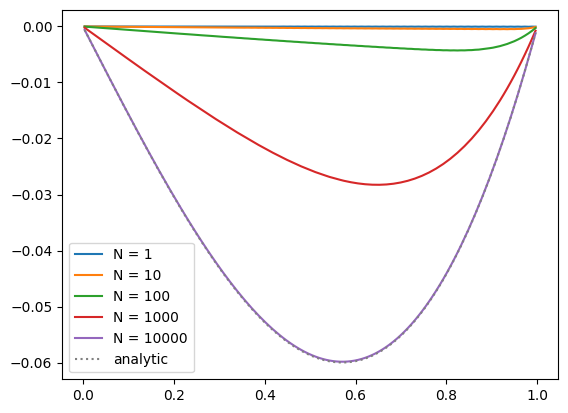

In [6]:
fig, ax = plt.subplots()

niters = [1, 10, 100, 1000, 10000]

for n in niters:

    # smooth n times
    for _ in range(n):
        smooth(g)
    
    ax.plot(g.x[g.ilo:g.ihi+1], g.phi[g.ilo:g.ihi+1], label=f"N = {n}")
    
    # reset phi to 0 for the next number of iterations
    g.phi[:] = 0.0

ax.plot(g.x[g.ilo:g.ihi+1], analytic(g.x[g.ilo:g.ihi+1]), ls=":",
        color="0.5", label="analytic")

ax.legend()
plt.show()

We see that as we increase the number of smoothing iterations, we get closer to the analytic solution.  Also note that the solution appears to be respecting our boundary conditions well.

It looks like only after 10000 iterations do we get close to the solution.

However, we haven't yet figured out how to tell how much relaxing is enough...

# Residual

We need to have a way to tell when to stop smoothing.

If we know the analytic solution, then we can just compare to that, and keep iterating until the error is small, but that kinda defeats the purpose.

Instead, we can measure how well we satisfy the discrete equation&mdash;this is called the *residual*.

$$r_i \equiv f_i - \frac{\phi^{(k)}_{i+1} - 2 \phi^{(k)}_i + \phi_{i-1}^{(k)}}{\Delta x^2}$$

We still need something to compare to, so we define the *source norm*, $\| f \|$, and we will pick a tolerance $\epsilon$ and iterate until:

$$\| r \| < \epsilon \| f \|$$

For the special case of a homogeneous source ($f = 0$), then we will iterate until

$$\| r \| < \epsilon$$

We will use the L2 norm:

$$\| e \|_2 \equiv \left ( \Delta x \sum_i |e_i|^2 \right )^{1/2}$$

## Implementation

Our grid class also includes a norm and residual method:

```python
    def norm(self, e):
        """compute the L2 norm of e that lives on our grid"""
        return np.sqrt(self.dx * np.sum(e[self.ilo:self.ihi+1]**2))

    def residual_norm(self):
        """compute the residual norm"""
        r = self.scratch_array()
        r[self.ilo:self.ihi+1] = self.f[self.ilo:self.ihi+1] - (self.phi[self.ilo+1:self.ihi+2] -
                                                2 * self.phi[self.ilo:self.ihi+1] +
                                                self.phi[self.ilo-1:self.ihi]) / self.dx**2
        return self.norm(r)
```

Now we'll go over the relaxation function that does smoothing until either a maximum number of iterations is taken or we reach a desired tolerance. If the tolerance is set to None, then the routine will take the full amount of iterations. 

We have the `TooManyIterations` class:
```python
class TooManyIterations(Exception):
    pass
```
as well as the `relax` method within the `PoissonRelaxation` class
```python
    def relax(self, tol=1.e-8, max_iters=200000, analytic=None):

        iter = 0
        fnorm = self.source_norm()
        if fnorm == 0.0:
            fnorm = 1.0

        self.fill_BCs()
        r = self.residual_norm()

        res_norm = []
        true_norm = []


        while iter < max_iters and (tol is None or r > tol * fnorm):

            self.phi[self.ilo:self.ihi+1:2] = 0.5 * (-self.dx**2 * self.f[self.ilo:self.ihi+1:2] +
                                                     self.phi[self.ilo+1:self.ihi+2:2] +
                                                     self.phi[self.ilo-1:self.ihi:2])

            self.fill_BCs()

            self.phi[self.ilo+1:self.ihi+1:2] = 0.5 * (-self.dx**2 * self.f[self.ilo+1:self.ihi+1:2] +
                                                       self.phi[self.ilo+2:self.ihi+2:2] +
                                                       self.phi[self.ilo:self.ihi:2])

            self.fill_BCs()

            r = self.residual_norm()
            res_norm.append(r / fnorm)

            if analytic is not None:
                true_norm.append(self.norm(self.phi - analytic(self.x)))

            iter += 1


        if tol is not None and iter >= max_iters:
            raise TooManyIterations(f"too many iteration, niter = {iter}")

        return res_norm, true_norm, iter
```

## Residual vs. Truncation Error

Let's look at how the residual error compares to the truncation error of our discretization.  We'll take a fixed number of iterations for our same model problem,

$$\phi^{\prime\prime} = \sin(x)$$

on $[0, 1]$ with homogeneous Dirichlet BCs.

nx = 16, true error = 0.0002489743563076079
nx = 32, true error = 6.224806537387576e-05
nx = 64, true error = 1.5562295551080843e-05


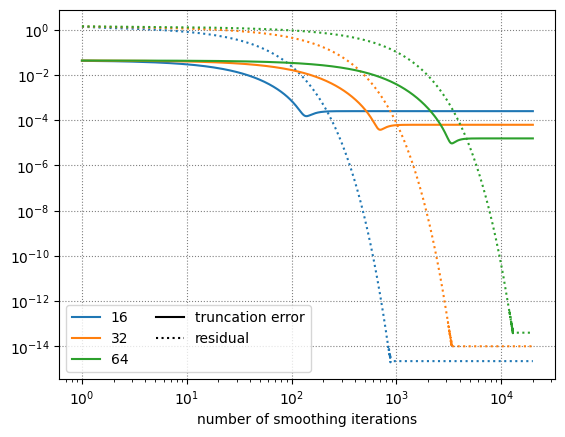

In [7]:
from matplotlib.lines import Line2D
fig, ax = plt.subplots()

for i, nx in enumerate([16, 32, 64]):
    g = pdemod.PoissonRelaxation(nx)
    g.f[:] = f(g.x)

    res_norm, true_norm, _ = g.relax(tol=None, max_iters=20000, analytic=analytic)
    n = np.arange(len(res_norm)) + 1
    
    ax.loglog(n, true_norm, label=f"{nx}", color=f"C{i}")
    ax.loglog(n, res_norm, ls=":", color=f"C{i}")
    
    print(f"nx = {nx}, true error = {true_norm[-1]}")

# manually add line types to the legend
handles, labels = ax.get_legend_handles_labels()
line1 = Line2D([0], [0], ls="-", color="k", label="truncation error")
line2 = Line2D([0], [0], ls=":", color="k", label="residual")
handles.extend([line1, line2])
ax.legend(handles=handles, ncol=2)

ax.set_xlabel("number of smoothing iterations")
ax.grid(ls=":", color="0.5")
plt.show()

Look at what this shows us:
    
* The truncation error (solid line) stalls at a much higher value than the residual (dotted).  

* The truncation error converges second order with the number of zones (look at the numbers printed during the run)

* As we increase the number of zones, we need more iterations until the residual drops to machine roundoff

* The residual error eventually reaches roundoff&mdash;this indicates that we satisfy the discrete equation "exactly"

**Important:**
The residual is telling us how well we satisfy the discrete form of Poisson's equation, but it is not telling us anything about whether the discrete approximation we are using for Poisson's equation is a good approximation.  That is our job as a scientist to assess.

We are using a second-order accurate discretization.  If needed, we could use a higher-order accurate method, although that would be more computationally expensive.

# Behavior of Single Modes

Smoothing takes a long time to converge to the solution.  To understand why this is, we
will look at the behavior of a single frequency mode under relaxation.  We'll use
the Laplace equation:

$$\phi^{\prime\prime} = 0$$

on $[0, 1]$ with homogeneous BCs as our test case.

**Tip:**
The solution to this is trivial&mdash;$\phi = 0$. So if we initialize the solution with a single-frequency sine way, and smooth a bit, we can compute the error easily.

We'll set our initial conditions like

$$\phi^{(0)} = \sin(2\pi m x)$$

where $m$ is an integer.

## Convergence of different modes

Let's see how different modes behave.  We'll write a function that makes a plot of the solution after several different numbers of iterations

In [8]:
def single_mode_comparison(m=1, nx=128):
    g = pdemod.PoissonRelaxation(nx)
    
    fig, ax = plt.subplots()
    
    for niter in [1, 10, 100, 1000]:
        # initialize
        g.phi[:] = np.sin(2*np.pi*m*g.x)
        
        # smooth
        g.relax(tol=None, max_iters=niter)
        
        ax.plot(g.x[g.ilo:g.ihi+1], g.phi[g.ilo:g.ihi+1],
                label=f"{niter} iters")
        
    ax.legend()
    ax.set_xlabel("$x$")
    ax.set_ylabel(r"$\phi(x)$")
    ax.grid(ls=":")
    
    return fig

Let's look at the behavior of $m=1$

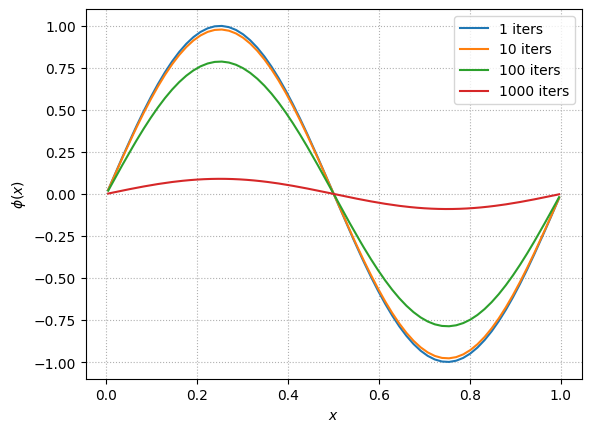

In [9]:
fig = single_mode_comparison(m=1)
plt.show()

We know that the solution is just $\phi = 0$, so any departure from that is error.  Even after 1000 iterations we can still see the sine behavior of the initial guess, so this is converging very slowly.

What about a higher mode? $m = 5$

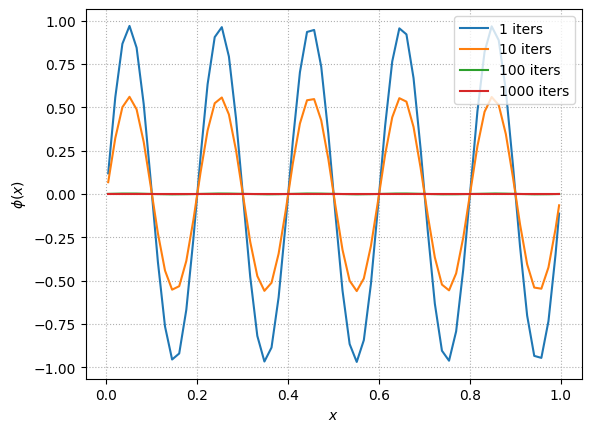

In [10]:
fig = single_mode_comparison(m=5)
plt.show()

This converges much faster!  After 100 iterations, it is hard to see the departure from $\phi = 0$

What about $m = 10$?

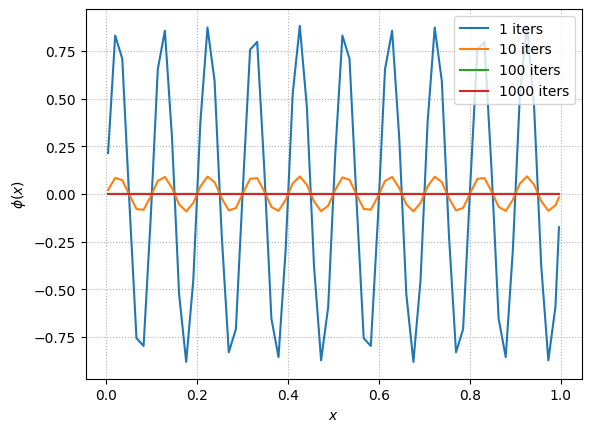

In [11]:
fig = single_mode_comparison(m=10)
plt.show()

This converges really fast!

**Important:**
What we are observing is that short wavelength noise (in terms of the number of zones across the wavelength) converges faster than long wavelength noise.

## Elements of Multigrid

We want to take advantage of the fact that long wavelength modes take a long time to relax away while the short wavelength modes relax very quickly.  

**Note:**
For this problem, any non-zero $\phi$ is the error, and since the Poisson equation is linear, so we can decompose $\phi(x)$ into its Fourier modes and what we observed above tells us that the short wavelength error modes will go away quickly (few smoothing iterations) while the long wavelength error modes will take much longer to relax away.

To see this, lets seed all 3 modes and look at how they relax:

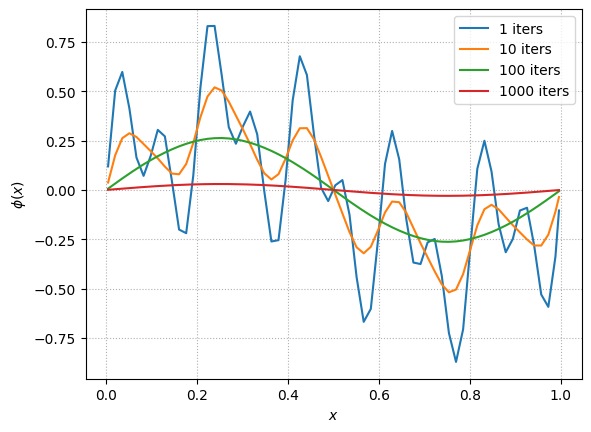

In [12]:
g = pdemod.PoissonRelaxation(128)
    
fig, ax = plt.subplots()
    
for niter in [1, 10, 100, 1000]:
    # initialize
    g.phi[:] = 1./3. * (np.sin(2*np.pi*g.x) +
                        np.sin(2*np.pi*5*g.x) +
                        np.sin(2*np.pi*10*g.x))
        
    # smooth
    g.relax(tol=None, max_iters=niter)
        
    ax.plot(g.x[g.ilo:g.ihi+1], g.phi[g.ilo:g.ihi+1],
            label=f"{niter} iters")
        
ax.legend()
ax.set_xlabel("$x$")
ax.set_ylabel(r"$\phi(x)$")
ax.grid(ls=":")
plt.show()

After 10 iterations, only the 2 longest wavelength modes persist and after 100, only the m = 1 mode survives.

**Tip:**
The [multigrid method](https://en.wikipedia.org/wiki/Multigrid_method) exploits this behavior by recognizing that _a long wavelength error on the original grid will have a shorter wavelength on a coarser grid_ (in terms of number of zones across a wavelength).

So multigrid coarsens the problem to accelerate the convergence of long wavelength errors.

To see this, let's look at an $m=2$ mode at several different grid resolutions.

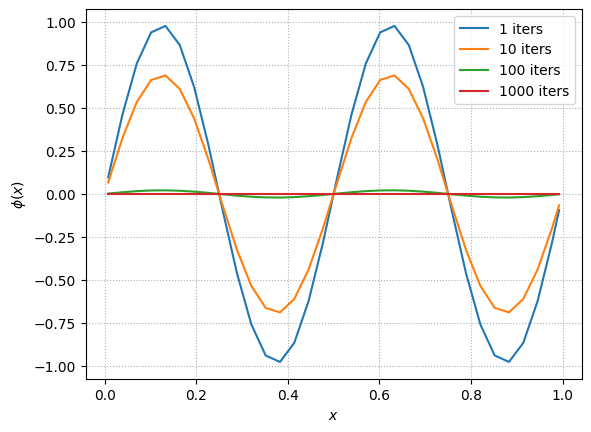

In [13]:
fig = single_mode_comparison(m=2, nx=64)
plt.show()

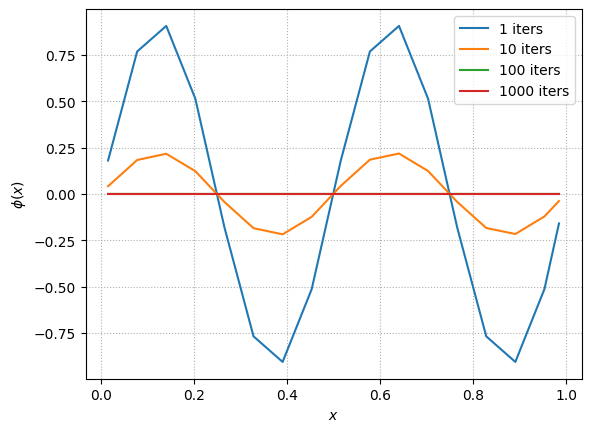

In [14]:
fig = single_mode_comparison(m=2, nx=32)
plt.show()

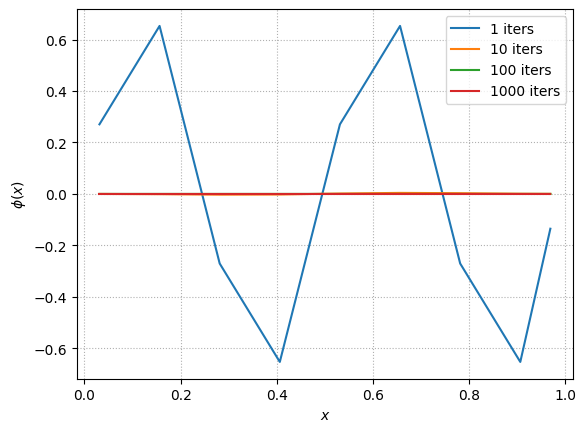

In [15]:
fig = single_mode_comparison(m=2, nx=16)
plt.show()

Notice that with 64 zones, the $m=2$ mode takes a long time to smooth away.  But as we make the grid coarser, that same mode smooths away much faster.  On the coarse grid, its wavelength, in terms of number of zones, is smaller, so fewer iterations are needed to communicate across the mode.

Multigrid algorithms coursen our problem and then bring what we learned on the coarse grid back up to the fine grid. More details can be found in the materials below:

https://zingale.github.io/computational_astrophysics/elliptic_multigrid/multigrid/multigrid.html

# Exercises (10 pt)

**Note:** If exercises are submitted by the end of class, all students get an extra 2 pts added to their scores.

## Exercise 1 - Muddiest Moment (2 pt)

What was the most confusing part of this lecture?

**Answer here**


## Exercise 2 - Another test problem (8 pt)

In this problem, we solve the differential equation
$$
\phi'' = - 4 \pi^2 \cos(2 \pi x).
$$

### Exercise 2(a) - Calculate true solution with sympy

Use sympy to solve the differential equation with the following code:
```python
# 1. Define the independent variable and unknown function
x = sp.symbols('x')
phi = sp.Function('phi')

# 2. Define the differential equation
ode = sp.Eq(phi(x).diff(x, 2), -4 * sp.pi**2 * sp.cos(2 * sp.pi * x))

# 3. Define the boundary conditions
bcs = {
    phi(0): 0,
    phi(1): 0
}

# 4. Solve the boundary value problem
sol = sp.dsolve(ode, phi(x), ics=bcs)
print(sol)
```

In [16]:
## Answer here


### Exercise 2(b) - Define function and grid objects (2 pt)

Define three functions:
1. `analytic`, which is the analytic solution to the differential equation
2. `f`, which is defined by $\phi''(x) = f(x)$ for our differential equation
3. Our grid object `g` with `nx=128` grid points. Make sure you also assign the `g.f` function attribute like we did in our class example.

In [17]:
## Answer here


### Exercise 2(c) - Relaxing to the solution (2 pt)

Lets now do relaxation / smoothing.  Just like our previous test problem where we don't know the amount of iterations that we need, lets iterate over $N = 1, 10, 100, 1000, 10000$, and compare our numerical solution to the analytic one.

Copy our in-class exercise for this new test case, and plot the comparison of our relaxation solution to our analytic one. Notice that we have more "modes" than we had in our first test case run.

In [18]:
## Answer here


### Exercise 2(d) - Comparing the Residual to the Truncation Error

Compare the residual to the truncation error, varying the number of smooting iterations to the number of radial gridpoints. Copy the code from the in-class exercise in the radial gridpoints and smoothing iterations investigated.

In [19]:
## Answer here
